<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/03_training_data_composition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 03 · Training-data composition (Experiment A)

**Question:** does emphasising recent applications improve fraud detection, once training-set size is controlled?

This notebook continues the completed baseline. It fixes the selected **unweighted LightGBM** configuration (15 leaves, 100 minimum child samples, 300 trees) and changes only training-data composition. Every fitted pipeline learns its own category vocabulary from its own training subset.

- Eligible history: months **0–4**; validation: **month 5**.
- Compare all history, the latest 1/2/3 complete months, and random historical samples with exactly the same respective sizes.
- Three paired seeds give **21 fits**. There is no hyperparameter search, class weighting, oversampling or monthly retraining.
- **Months 6–7 are excluded from the data loaded for modelling.** There is no test-evaluation switch.

Run after `00_data_preparation.ipynb`, from top to bottom in Colab (CPU) or locally. No baseline model files or `src/` imports are required. The baseline configuration is explicitly recorded below. Results are generated by your run, not pre-filled.


## 1. Paths and prerequisites

Colab reads `MyDrive/BT4012_grp_proj/processed/baf_clean.parquet` and `preparation_manifest.json`. Locally, put this notebook in `notebooks/`; the prepared pair belongs in `data/processed/`. Keep the same paths used in preparation and baseline modelling. The raw CSV is not needed here.


In [ ]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

CLEAN_PATH = PROCESSED_DIR / 'baf_clean.parquet'
MANIFEST_PATH = PROCESSED_DIR / 'preparation_manifest.json'

print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Project:', PROJECT_DIR)
print('Raw CSV:', RAW_PATH)
print('Prepared data:', CLEAN_PATH)


Mounted at /content/drive
Runtime: Google Colab
Project: /content/drive/MyDrive/BT4012_grp_proj
Raw CSV: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Prepared data: /content/drive/MyDrive/BT4012_grp_proj/processed/baf_clean.parquet


## 2. Fixed experiment settings

`SEEDS` controls both historical sampling and model randomness. Within a seed, all conditions use the same model seed. Recent-window rows are unchanged across seeds; Historical K rows vary. Consequently, the spread combines model randomness and (for Historical K) sampling randomness. It is **not** uncertainty across independent future months.

Keep all three seeds for report results. For a quick smoke run, use `[42]`, but label that run as preliminary. Model files are off by default to avoid saving 21 models; validation predictions and training row IDs are saved for auditing. Results are written after each fit so completed work survives a later interruption. Restarting the notebook creates a new run rather than silently reusing old results.


In [ ]:
import importlib.util
import subprocess

required_packages = {'lightgbm': 'lightgbm>=4.0', 'pyarrow': 'pyarrow>=14.0'}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    if IN_COLAB:
        subprocess.check_call([
            sys.executable, '-m', 'pip', 'install', '-q', *missing_packages,
        ])
    else:
        raise ImportError('Missing dependencies. Run: python -m pip install -r requirements.txt')

import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from uuid import uuid4

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder


SEEDS = [42, 43, 44]
N_JOBS = 2
VERIFY_CHECKSUM = True
SAVE_MODELS = False
SAVE_PREDICTIONS = True
SAVE_TRAIN_IDS = True
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]
RECENT_MONTH_COUNTS = [1, 2, 3]
TRAIN_MONTHS = [0, 1, 2, 3, 4]
VALIDATION_MONTHS = [5]
LGBM_TREES = 300
FIXED_PARAMS = {'num_leaves': 15, 'min_child_samples': 100}
RUN_LABEL = 'training_composition_unweighted'

assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
assert all(0 < n <= len(TRAIN_MONTHS) for n in RECENT_MONTH_COUNTS)

run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RUN_NAME = f'{RUN_LABEL}_{run_id}'
RESULTS_DIR = PROJECT_DIR / 'results' / 'training_composition' / RUN_NAME
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'training_composition' / RUN_NAME
FIGURES_DIR = RESULTS_DIR / 'figures'

for directory in [RESULTS_DIR, FIGURES_DIR, ARTIFACTS_DIR]:
    directory.mkdir(parents=True, exist_ok=False)

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 200,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

print('Results:', RESULTS_DIR)
print('Artifacts:', ARTIFACTS_DIR)
print('Planned fits:', (1 + 2 * len(RECENT_MONTH_COUNTS)) * len(SEEDS))


Results: /content/drive/MyDrive/BT4012_grp_proj/results/training_composition/training_composition_unweighted_20261115T175457Z_55dcc3
Artifacts: /content/drive/MyDrive/BT4012_grp_proj/artifacts/training_composition/training_composition_unweighted_20261115T175457Z_55dcc3
Planned fits: 21


## 3. Load only development months

The manifest defines the shared feature schema and deterministic missing-value decoding established in preparation. We reuse that schema across conditions, including the training-history constant-feature exclusion. We do **not** refit global feature selection for individual windows. All learned model preprocessing is fitted separately inside each condition.

The optional checksum reads file bytes for integrity; it does not evaluate held-out labels. Parquet filtering below loads only months 0–5 into the modelling dataframe.


In [ ]:
def file_sha256(path):
    """Return a chunked SHA-256 digest to verify the prepared file matches its manifest."""
    digest = hashlib.sha256()

    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)

    return digest.hexdigest()


if not CLEAN_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError('Run 00_data_preparation.ipynb first with the same project paths.')

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)

if manifest.get('schema_version') != 1:
    raise ValueError('Unsupported preparation manifest version.')

if VERIFY_CHECKSUM and file_sha256(CLEAN_PATH) != manifest['prepared_sha256']:
    raise ValueError('Parquet fingerprint differs from the manifest; rerun preparation.')


TARGET = manifest['target']
MONTH = manifest['month_column']
ROW_ID = manifest['row_id_column']
FEATURES = manifest['features']
NUMERICAL = manifest['numerical_features']
CATEGORICAL = manifest['categorical_features']

if manifest['split_months']['train'] != TRAIN_MONTHS:
    raise ValueError('This experiment expects training months 0–4.')

if manifest['split_months']['validation'] != VALIDATION_MONTHS:
    raise ValueError('This experiment expects validation month 5.')

if set(FEATURES) != set(NUMERICAL + CATEGORICAL):
    raise ValueError('Inconsistent feature lists in preparation manifest.')

if set(FEATURES) & {TARGET, MONTH, ROW_ID}:
    raise ValueError('Target, month or row ID cannot be predictors.')

df = pd.read_parquet(
    CLEAN_PATH,
    filters=[(MONTH, 'in', TRAIN_MONTHS + VALIDATION_MONTHS)],
)

if list(df.columns) != manifest['columns'] or not df[ROW_ID].is_unique:
    raise ValueError('Prepared schema or row identifiers are inconsistent.')

for column in CATEGORICAL:
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

# Sort by original row ID to make sampling reproducible if parquet row order changes.
history = df[df[MONTH].isin(TRAIN_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
validation = df[df[MONTH].isin(VALIDATION_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
del df

for name, frame in [('train', history), ('validation', validation)]:
    if len(frame) != manifest['split_counts'][name]:
        raise ValueError(f'{name} row count differs from the preparation manifest.')

    if not frame[TARGET].isin([0, 1]).all() or frame[TARGET].nunique() != 2:
        raise ValueError(f'{name} must contain valid labels and both classes.')

X_validation = validation[FEATURES]
y_validation = validation[TARGET].to_numpy()
validation_ties = np.random.default_rng(2026).random(len(validation))

display(history.groupby(MONTH)[TARGET].agg(
    applications='size', frauds='sum', fraud_rate='mean',
))
print('Validation applications:', len(validation))
print('Validation frauds:', int(y_validation.sum()))
print('Predictors:', len(FEATURES))


,applications,frauds,fraud_rate
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371


Validation applications: 119323
Validation frauds: 1411
Predictors: 29


## 4. Define the seven training conditions

| Condition | Training rows | What it tells us |
|---|---|---|
| All history | All months 0–4 | Practical maximum-data reference |
| Recent 1 month | All month 4 rows | Latest complete month |
| Historical K: 1-month size | K random rows from months 0–4 | Same-size reference for Recent 1 |
| Recent 2 months | All months 3–4 rows | Latest two complete months |
| Historical K: 2-month size | K random rows from months 0–4 | Same-size reference for Recent 2 |
| Recent 3 months | All months 2–4 rows | Latest three complete months |
| Historical K: 3-month size | K random rows from months 0–4 | Same-size reference for Recent 3 |

K is calculated from the actual prepared data, not hard-coded. Historical K **includes** recent months in its sampling pool; it is not an old-only sample. Sampling is uniform without replacement and is not stratified by fraud label. Matching row count does not match fraud count or prevalence, which we therefore record explicitly.

Within each seed, historical samples use prefixes of one shuffled history index, making smaller K samples nested inside larger ones. This pairing reduces arbitrary differences between K settings but does not create independent samples.

BAF gives month-level time, so we use complete recent months rather than assuming CSV order provides timestamps within a month. This is one fixed training cutoff, not a rolling retraining experiment.


In [ ]:
conditions = [{'condition': 'all_history', 'kind': 'all', 'recent_months': 0,
               'k': len(history), 'months': TRAIN_MONTHS}]

for n_months in RECENT_MONTH_COUNTS:
    months = TRAIN_MONTHS[-n_months:]
    k = int(history[MONTH].isin(months).sum())

    conditions.extend([
        {'condition': f'recent_{n_months}m', 'kind': 'recent',
         'recent_months': n_months, 'k': k, 'months': months},
        {'condition': f'historical_k_{n_months}m', 'kind': 'historical',
         'recent_months': n_months, 'k': k, 'months': TRAIN_MONTHS},
    ])

condition_table = pd.DataFrame(conditions)
condition_table.to_csv(RESULTS_DIR / 'condition_plan.csv', index=False)
display(condition_table)


def select_training_rows(condition, historical_order):
    """Select exactly K eligible rows without consulting validation or test labels.

    Recent conditions include complete months. Historical conditions take a prefix
    of a seed-specific random permutation, so no row repeats within a subset.
    Sorting afterwards keeps training order consistent across conditions.
    """
    if condition['kind'] == 'all':
        subset = history
    elif condition['kind'] == 'recent':
        subset = history[history[MONTH].isin(condition['months'])]
    else:
        subset = history.iloc[historical_order[:condition['k']]]

    subset = subset.sort_values(ROW_ID)

    if len(subset) != condition['k'] or not subset[ROW_ID].is_unique:
        raise ValueError('Training subset size or uniqueness check failed.')

    if subset[TARGET].nunique() != 2:
        raise ValueError('Training subset must contain both classes.')

    return subset


,condition,kind,recent_months,k,months
0,all_history,all,0,675666,"[0, 1, 2, 3, 4]"
1,recent_1m,recent,1,127691,[4]
2,historical_k_1m,historical,1,127691,"[0, 1, 2, 3, 4]"
3,recent_2m,recent,2,278627,"[3, 4]"
4,historical_k_2m,historical,2,278627,"[0, 1, 2, 3, 4]"
5,recent_3m,recent,3,415606,"[2, 3, 4]"
6,historical_k_3m,historical,3,415606,"[0, 1, 2, 3, 4]"


## 5. Fresh LightGBM preprocessing for every fit

Numeric NaNs pass through to LightGBM. Categorical missing values receive an explicit label; an OrdinalEncoder learns categories only from the current training subset. The resulting column positions are explicitly declared categorical, so codes are not interpreted as ordered numbers. Unseen validation categories become −1 (missing for LightGBM).

The fixed settings match the selected baseline. No early stopping or per-condition tuning is used: those would change model complexity across conditions. Because this configuration was selected using all-history validation results, this is a comparison under a common configuration, **not** a comparison of each strategy's individually optimised best model.


In [ ]:
def build_lightgbm(seed):
    """Return a fresh subset-specific pipeline and categorical fit arguments."""
    categorical_pipeline = Pipeline([
        ('impute', SimpleImputer(
            strategy='constant',
            fill_value='__MISSING__',
            keep_empty_features=True,
        )),
        ('encode', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1,
            dtype=np.int32,
        )),
    ])

    # ColumnTransformer puts numeric columns first and category codes second.
    preprocessing = ColumnTransformer([
        ('numeric', 'passthrough', NUMERICAL),
        ('categorical', categorical_pipeline, CATEGORICAL),
    ])

    classifier = LGBMClassifier(
        objective='binary',
        n_estimators=LGBM_TREES,
        learning_rate=0.05,
        num_leaves=FIXED_PARAMS['num_leaves'],
        min_child_samples=FIXED_PARAMS['min_child_samples'],
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        class_weight=None,
        scale_pos_weight=1.0,
        random_state=seed,
        n_jobs=N_JOBS,
        verbosity=-1,
    )

    categorical_positions = list(range(
        len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL),
    ))

    return Pipeline([
        ('preprocessing', preprocessing),
        ('classifier', classifier),
    ]), {'classifier__categorical_feature': categorical_positions}


## 6. Evaluation rules

**Primary metric:** validation average precision (AP), using sklearn's `average_precision_score`. Keep this choice fixed rather than picking whichever metric favours a preferred condition.

**Recall at 5% FPR:** select the least restrictive validation score cutoff whose empirical FPR is at most 0.05. FPR = FP / (FP + TN): the fraction of legitimate applications flagged. It is not the fraction of the review queue that is legitimate. Ties may keep achieved FPR slightly below 5%. Each fitted model needs its own cutoff.

**Review capacities:** separately evaluate the top 1%, 2% and 5% of applications. Exact top-K capacity and a 5% FPR constraint are different policies. The same label-independent tie breakers are used for every fit. Validation thresholds and metrics are development results; their future performance is not guaranteed.


In [ ]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


## 7. Save the configuration, then run the experiment

Per-fit CSVs include training prevalence, monthly composition, AP, ROC-AUC, recall at the FPR ceiling, achieved FPR, precision and workload. Prediction files retain row IDs for later comparison. Large artifacts belong outside Git; commit the notebook and useful small result tables/figures.

The run status is initially `running` and changes to `complete` only after all fits finish. Partial results can be inspected after an interruption, but do not use them as the completed seven-condition comparison.


In [ ]:
def json_safe(value):
    """
    Convert nested results into standards-compliant JSON values.
    Nonfinite floats become null; threshold direction is recorded separately below.
    """
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}

    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]

    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None

    if isinstance(value, np.generic):
        return value.item()

    return value



def write_json(filename, payload):
    """Write JSON with explicit nulls for nonfinite numeric values."""
    with open(RESULTS_DIR / filename, 'w', encoding='utf-8') as handle:
        json.dump(json_safe(payload), handle, indent=2, allow_nan=False)


run_info = {
    'run_name': RUN_NAME,
    'status': 'running',
    'preparation_id': manifest['preparation_id'],
    'prepared_sha256': manifest['prepared_sha256'],
    'train_months': TRAIN_MONTHS,
    'validation_months': VALIDATION_MONTHS,
    'test_evaluated': False,
    'seeds': SEEDS,
    'selection_metric': 'mean validation average precision across seeds',
    'class_imbalance_treatment': 'none',
    'conditions': conditions,
    'model_parameters': build_lightgbm(SEEDS[0])[0].named_steps['classifier'].get_params(),
    'fpr_target': FPR_TARGET,
    'review_capacities': REVIEW_CAPACITIES,
    'save_models': SAVE_MODELS,
    'save_predictions': SAVE_PREDICTIONS,
    'save_train_ids': SAVE_TRAIN_IDS,
    'versions': {
        'python': platform.python_version(), 'pandas': pd.__version__,
        'numpy': np.__version__, 'sklearn': sklearn.__version__,
        'lightgbm': lightgbm.__version__, 'joblib': joblib.__version__,
    },
}
write_json('run_info.json', run_info)
write_json('preparation_manifest.json', manifest)

metric_rows = []
capacity_frames = []
composition_frames = []

for seed in SEEDS:
    historical_order = np.random.default_rng(seed).permutation(len(history))

    for condition in conditions:
        name = condition['condition']
        subset = select_training_rows(condition, historical_order)
        estimator, fit_arguments = build_lightgbm(seed)
        start = time.perf_counter()

        estimator.fit(subset[FEATURES], subset[TARGET], **fit_arguments)
        fit_seconds = time.perf_counter() - start
        scores = estimator.predict_proba(X_validation)[:, 1]

        if not np.isfinite(scores).all():
            raise ValueError(f'Nonfinite predictions: {name}, seed {seed}')

        cutoff = threshold_for_fpr(y_validation, scores, FPR_TARGET)
        operating = at_threshold(y_validation, scores, cutoff)
        assert operating['fpr'] <= FPR_TARGET + 1e-12

        metric_rows.append({
            'condition': name, 'seed': seed, 'kind': condition['kind'],
            'recent_months': condition['recent_months'],
            'training_rows': len(subset), 'training_frauds': int(subset[TARGET].sum()),
            'training_fraud_rate': float(subset[TARGET].mean()),
            'fit_seconds': fit_seconds,
            'validation_threshold': cutoff,
            'threshold_is_positive_infinity': bool(np.isposinf(cutoff)),
            **ranking_metrics(y_validation, scores, 'lightgbm'),
            **{f'at_fpr_{key}': value for key, value in operating.items()},
        })

        capacity = capacity_table(
            y_validation, scores, REVIEW_CAPACITIES, validation_ties,
        )
        capacity.insert(0, 'seed', seed)
        capacity.insert(0, 'condition', name)
        capacity_frames.append(capacity)

        composition = subset.groupby(MONTH)[TARGET].agg(
            applications='size', frauds='sum', fraud_rate='mean',
        ).reset_index()
        composition.insert(0, 'seed', seed)
        composition.insert(0, 'condition', name)
        composition_frames.append(composition)

        prefix = f'{name}_seed_{seed}'

        if SAVE_PREDICTIONS:
            predictions = validation[[ROW_ID, MONTH, TARGET]].copy()
            predictions['score'] = scores
            predictions.to_parquet(ARTIFACTS_DIR / f'{prefix}_validation.parquet', index=False)

        if SAVE_TRAIN_IDS:
            subset[[ROW_ID]].to_parquet(ARTIFACTS_DIR / f'{prefix}_train_ids.parquet', index=False)

        if SAVE_MODELS:
            joblib.dump(estimator, ARTIFACTS_DIR / f'{prefix}.joblib', compress=3)

        # Checkpoint small tables after every successful fit.
        pd.DataFrame(metric_rows).to_csv(RESULTS_DIR / 'validation_metrics.csv', index=False)
        pd.concat(capacity_frames).to_csv(RESULTS_DIR / 'validation_capacity.csv', index=False)
        pd.concat(composition_frames).to_csv(RESULTS_DIR / 'training_month_composition.csv', index=False)

        print(
            f'{len(metric_rows)}/{len(conditions) * len(SEEDS)} | {name} | '
            f'seed={seed} | K={len(subset):,} | '
            f'AP={metric_rows[-1]["average_precision"]:.5f} | '
            f'recall@5%FPR={operating["recall"]:.3%} | fit={fit_seconds:.1f}s'
        )

        # Do not hold all 21 fitted models in memory.
        del estimator, subset

metrics = pd.DataFrame(metric_rows)
capacities = pd.concat(capacity_frames, ignore_index=True)
run_info['status'] = 'complete'
run_info['completed_fits'] = len(metrics)
write_json('run_info.json', run_info)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


1/21 | all_history | seed=42 | K=675,666 | AP=0.18499 | recall@5%FPR=54.500% | fit=38.1s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


2/21 | recent_1m | seed=42 | K=127,691 | AP=0.17030 | recall@5%FPR=51.665% | fit=5.1s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


3/21 | historical_k_1m | seed=42 | K=127,691 | AP=0.16449 | recall@5%FPR=52.232% | fit=7.8s


... (32 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


20/21 | recent_3m | seed=44 | K=415,606 | AP=0.17893 | recall@5%FPR=53.579% | fit=23.8s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


21/21 | historical_k_3m | seed=44 | K=415,606 | AP=0.17900 | recall@5%FPR=53.792% | fit=20.3s


## 8. Aggregate results and compare matched pairs

Means and sample standard deviations summarise the seeds. Standard deviations are descriptive, not confidence intervals or significance tests. With one seed, standard deviation is undefined.

The main recency contrast is **Recent K minus Historical K**, paired by seed and K. Positive AP differences favour recency at equal sample size. Also compare **Recent K minus All history** to assess the practical trade-off from discarding data. All-history comparisons do not isolate recency from sample size.


In [ ]:
summary = metrics.groupby('condition', sort=False).agg(
    seeds=('seed', 'nunique'),
    training_rows=('training_rows', 'first'),
    fraud_rate_mean=('training_fraud_rate', 'mean'),
    ap_mean=('average_precision', 'mean'),
    ap_std=('average_precision', 'std'),
    recall_at_fpr_mean=('at_fpr_recall', 'mean'),
    recall_at_fpr_std=('at_fpr_recall', 'std'),
    achieved_fpr_mean=('at_fpr_fpr', 'mean'),
    precision_at_fpr_mean=('at_fpr_precision', 'mean'),
    alert_rate_mean=('at_fpr_alert_rate', 'mean'),
    fit_seconds_mean=('fit_seconds', 'mean'),
).reset_index()
summary = summary.sort_values('ap_mean', ascending=False, kind='stable')
summary.to_csv(RESULTS_DIR / 'condition_summary.csv', index=False)
display(summary.round(5))

paired_rows = []
lookup = metrics.set_index(['condition', 'seed'])

for n_months in RECENT_MONTH_COUNTS:
    recent_name = f'recent_{n_months}m'

    for comparator in [f'historical_k_{n_months}m', 'all_history']:
        for seed in SEEDS:
            recent = lookup.loc[(recent_name, seed)]
            reference = lookup.loc[(comparator, seed)]
            paired_rows.append({
                'recent_condition': recent_name, 'comparator': comparator, 'seed': seed,
                'ap_delta': recent['average_precision'] - reference['average_precision'],
                'recall_delta': recent['at_fpr_recall'] - reference['at_fpr_recall'],
                'training_fraud_rate_delta': recent['training_fraud_rate'] - reference['training_fraud_rate'],
            })

paired = pd.DataFrame(paired_rows)
paired.to_csv(RESULTS_DIR / 'paired_seed_differences.csv', index=False)
paired_summary = paired.groupby(['recent_condition', 'comparator'], sort=False).agg(
    ap_delta_mean=('ap_delta', 'mean'),
    ap_delta_std=('ap_delta', 'std'),
    recall_delta_mean=('recall_delta', 'mean'),
    seeds_with_positive_ap_delta=('ap_delta', lambda x: int((x > 0).sum())),
).reset_index()
paired_summary.to_csv(RESULTS_DIR / 'paired_summary.csv', index=False)
display(paired_summary.round(5))

capacity_summary = capacities.groupby(['condition', 'capacity'], sort=False).agg(
    recall_mean=('recall', 'mean'), recall_std=('recall', 'std'),
    precision_mean=('precision', 'mean'),
    frauds_flagged_mean=('frauds_flagged', 'mean'),
    legitimate_reviewed_mean=('legitimate_reviewed', 'mean'),
    frauds_flagged_per_10000=('frauds_flagged_per_10000', 'mean'),
    legitimate_reviewed_per_10000=('legitimate_reviewed_per_10000', 'mean'),
).reset_index()
capacity_summary.to_csv(RESULTS_DIR / 'capacity_summary.csv', index=False)
display(capacity_summary.round(4))

# This is a development ranking, not an automatic instruction to deploy a policy.
write_json('development_ranking.json', {
    'top_condition_by_mean_ap': summary.iloc[0]['condition'],
    'criterion': 'mean validation AP; first planned condition breaks an exact tie',
    'final_policy_selected': False,
    'test_evaluated': False,
})


,condition,seeds,training_rows,fraud_rate_mean,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,alert_rate_mean,fit_seconds_mean
0,all_history,3,675666,0.00998,0.18567,0.00134,0.54359,0.00142,0.04999,0.11513,0.05583,36.67563
6,historical_k_3m,3,415606,0.00996,0.18265,0.00493,0.54028,0.00537,0.04999,0.11451,0.05579,20.21338
5,recent_3m,3,415606,0.00973,0.18169,0.00302,0.53626,0.00082,0.04999,0.11376,0.05575,23.34437
4,historical_k_2m,3,278627,0.00993,0.17700,0.00442,0.53343,0.00217,0.04999,0.11322,0.05571,14.66372
3,recent_2m,3,278627,0.01021,0.17647,0.00133,0.53603,0.00550,0.04999,0.11371,0.05574,15.91930
2,historical_k_1m,3,127691,0.01023,0.16758,0.00406,0.51736,0.00496,0.04999,0.11019,0.05552,8.21729
1,recent_1m,3,127691,0.01137,0.16756,0.00241,0.51642,0.00108,0.04999,0.11001,0.05551,5.09948


,recent_condition,comparator,ap_delta_mean,ap_delta_std,recall_delta_mean,seeds_with_positive_ap_delta
0,recent_1m,historical_k_1m,-0.00002,0.00568,-0.00094,1
1,recent_1m,all_history,-0.01810,0.00306,-0.02717,0
2,recent_2m,historical_k_2m,-0.00052,0.00573,0.00260,1
3,recent_2m,all_history,-0.00919,0.00081,-0.00756,0
4,recent_3m,historical_k_3m,-0.00096,0.00208,-0.00402,1
5,recent_3m,all_history,-0.00398,0.00420,-0.00732,1


,condition,capacity,recall_mean,recall_std,precision_mean,frauds_flagged_mean,legitimate_reviewed_mean,frauds_flagged_per_10000,legitimate_reviewed_per_10000
0,all_history,0.01,0.2374,0.0056,0.2808,335.0000,858.0000,28.0751,71.9057
1,all_history,0.02,0.3470,0.0008,0.2052,489.6667,1896.3333,41.0371,158.9244
2,all_history,0.05,0.5228,0.0022,0.1236,737.6667,5228.3333,61.8210,438.1664
3,recent_1m,0.01,0.2195,0.0022,0.2596,309.6667,883.3333,25.9520,74.0288
4,recent_1m,0.02,0.3291,0.0059,0.1946,464.3333,1921.6667,38.9140,161.0475
5,recent_1m,0.05,0.4980,0.0045,0.1178,702.6667,5263.3333,58.8878,441.0996
6,historical_k_1m,0.01,0.2249,0.0060,0.2660,317.3333,875.6667,26.5945,73.3862
7,historical_k_1m,0.02,0.3270,0.0073,0.1934,461.3333,1924.6667,38.6626,161.2989
8,historical_k_1m,0.05,0.4952,0.0047,0.1171,698.6667,5267.3333,58.5526,441.4349
9,recent_2m,0.01,0.2275,0.0051,0.2691,321.0000,872.0000,26.9018,73.0790


## 9. Report figures

Error bars show one standard deviation across seeds. All conditions share the same validation month. Differences are not independent temporal replications.


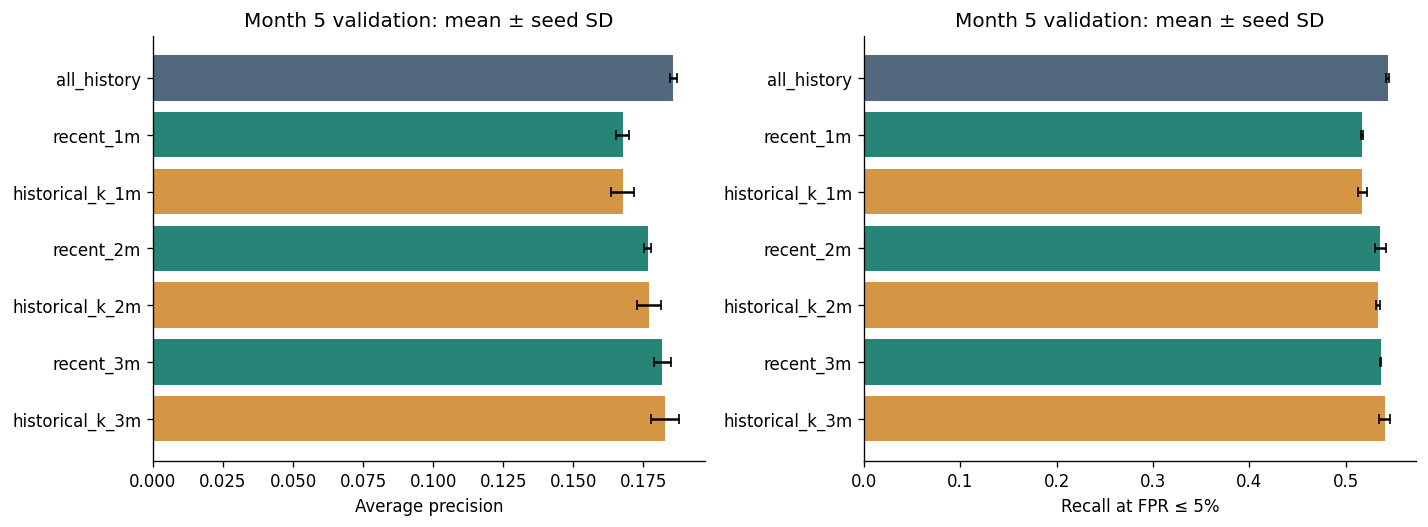

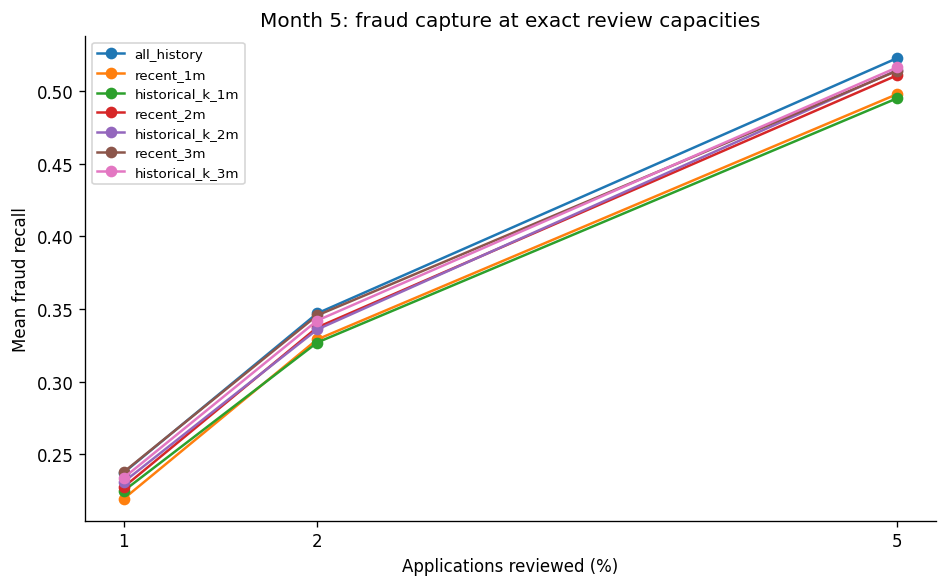

Completed results: /content/drive/MyDrive/BT4012_grp_proj/results/training_composition/training_composition_unweighted_20261115T175457Z_55dcc3
Predictions / row membership / optional models: /content/drive/MyDrive/BT4012_grp_proj/artifacts/training_composition/training_composition_unweighted_20261115T175457Z_55dcc3


In [ ]:
ordered = summary.set_index('condition').loc[condition_table['condition']]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(ordered))

for ax, mean_column, std_column, label in [
    (axes[0], 'ap_mean', 'ap_std', 'Average precision'),
    (axes[1], 'recall_at_fpr_mean', 'recall_at_fpr_std', 'Recall at FPR ≤ 5%'),
]:
    ax.barh(
        positions, ordered[mean_column],
        xerr=ordered[std_column].fillna(0), capsize=3,
        color=['#52687c' if name == 'all_history' else
               '#278577' if name.startswith('recent') else '#d49644'
               for name in ordered.index],
    )
    ax.set_yticks(positions, ordered.index)
    ax.invert_yaxis()
    ax.set_xlabel(label)
    ax.set_title('Month 5 validation: mean ± seed SD')

fig.tight_layout()
fig.savefig(FIGURES_DIR / 'composition_metrics.png', bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))

for condition in condition_table['condition']:
    frame = capacity_summary[capacity_summary['condition'] == condition]
    ax.plot(100 * frame['capacity'], frame['recall_mean'], marker='o', label=condition)

ax.set(xlabel='Applications reviewed (%)', ylabel='Mean fraud recall',
       title='Month 5: fraud capture at exact review capacities')
ax.set_xticks([100 * c for c in REVIEW_CAPACITIES])
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'composition_review_capacity.png', bbox_inches='tight')
plt.show()
plt.close(fig)

print('Completed results:', RESULTS_DIR)
print('Predictions / row membership / optional models:', ARTIFACTS_DIR)


## 10. Interpret the results before moving to imbalance treatment

Fill in this table after running:

| Question | Evidence / interpretation |
|---|---|
| Does recency help at equal K? | Paired AP differences versus Historical K; check direction across seeds and training fraud rates. |
| Is discarding history practically worthwhile? | Compare recent windows against All history on AP, recall at review budgets and runtime. |
| Do metrics disagree? | Keep AP as the primary criterion; describe the recall/workload trade-off rather than quietly switching objectives. |
| Are differences small or seed-sensitive? | Avoid calling a narrow lead conclusive. All history remains a reasonable reference. |
| Which condition will Stage B use? | Record the chosen policy, K/months, primary evidence and limitations. Do not pick the best individual seed. |

**Three possible outcomes:**

1. Recent K beats Historical K but loses to All history: recency appears useful per training row, but retaining more data still helps overall.
2. Recent K beats both: a recent window is a promising development choice; it still needs final temporal testing.
3. Recent K loses to both: these results do not support discarding older observations under this configuration.

A historical random sample may also rank highest. If chosen for Stage B, carry its sampling rule, K and fixed seeds forward; do not select a lucky sample after inspecting scores. A seed-averaged comparison does not automatically define a prediction ensemble.

**Limits:** matching K controls total training size but not fraud count, prevalence or all aspects of feature composition. We observe performance differences; we do not prove a particular type of drift. Three seeds share one validation month. The LightGBM configuration was already selected on month 5 with all history. Later model families may respond differently to training windows and need the planned limited transfer check.

**Next (B):** freeze a training-data policy and compare no treatment, class weighting and the agreed undersampling settings. Keep an all-history/unweighted reference. Do not revisit test months to decide these settings. Final evaluation must use model-specific thresholds selected on validation, with achieved future FPR reported separately from retrospective recall-at-FPR.

**Files to share with the team:** this notebook plus `condition_summary.csv`, `paired_summary.csv`, `capacity_summary.csv`, `run_info.json` and figures. Keep large `artifacts/` and `data/` files out of Git. Commit results only after confirming `run_info.json` says `complete`.

**Business interpretation:** flagged fraud labels are not established fraud prevented, and legitimate reviews are not necessarily rejected customers. No monetary savings are inferred. Acknowledge AI assistance according to your module requirements and make sure the team can explain the code.
